# Chapter 79: State Capacity, Extractive Institutions, and Development

This notebook reruns four worked examples from the chapter: a ruler's horizon and restraint, windfall claims under weak commitment, an extractive elite's tax choice, and an officeholder deciding on tax capacity. Every number is one of the chapter's hypothetical teaching numbers, not historical data; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def ruler_value(first, later, s, delta, cost=0.0):
    """Two-period expected ruler value: first - cost + s delta later.

    Principle: olson-stationary-bandit-model (ch079). Book: weight 0.85 x 0.90 = 0.765;
    45 + 0.765(15) = 56.475; 38.5 + 0.765(38.5) = 67.9525; 45.5 - 8 + 0.765(45.5) = 72.3075;
    at s = 0.20 the weight is 0.18, giving 47.7 and 45.69. Returns {"weight", "value"}.
    """
    w = s * delta
    return {"weight": w, "value": first - cost + w * later}


def voracity(resources, services, transfers, windfall, blocs, demand, cap=None):
    """Windfall claims ledger: each bloc demands ``demand`` extra; optional cap on new transfers.

    Principle: voracity-effect (ch079). Book: 150 - 60 - 45 = 45 before; with windfall 30 and four
    blocs demanding 12, transfers 93, multiplier 48/30 = 1.6, investment 180 - 60 - 93 = 27;
    with a cap of 18, investment 180 - 60 - (45 + 18) = 57. Returns new_claims, transfers,
    multiplier, investment_before, investment.
    """
    new = blocs * demand if cap is None else min(cap, blocs * demand)
    total = transfers + new
    return {"new_claims": new, "transfers": total, "multiplier": new / windfall,
            "investment_before": resources - services - transfers,
            "investment": resources + windfall - services - total}


def extraction_revenue(e0, tau):
    """Output y = e0(1 - tau), elite revenue R = tau y, producers keep y - R.

    Principle: extractive-institutions (ch079). Book: e0 = 160 at tau 0.5 gives 80, 40, 40; at 0.25
    gives 120, 30, 90; e0 = 180 at 0.25 gives 135 and 33.75. Revenue peaks at tau = 0.5.
    """
    y = e0 * (1 - tau)
    return {"output": y, "revenue": tau * y, "producers": y - tau * y}


def fiscal_capacity(base, rate, q):
    """Collected revenue T = q tau B.

    Principle: fiscal-capacity-state-building (ch079). Book: 0.45(0.18)(2,000) = 162;
    0.70(0.18)(2,000) = 252; 0.70(0.18)(2,080) = 262.08.
    """
    return q * rate * base


plt.rcParams.update(HOUSE_RC)


public = SimpleNamespace(ruler_value=ruler_value, voracity=voracity, extraction_revenue=extraction_revenue, fiscal_capacity=fiscal_capacity)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'olson-stationary-bandit-model': {'heavy_now': 45,
                                   'heavy_later': 15,
                                   'moderate': 38.5,
                                   'patrol_cost': 8,
                                   'patrol_rev': 45.5,
                                   's': 0.85,
                                   'delta': 0.9,
                                   'weight': 0.765,
                                   'heavy': 56.475,
                                   'moderate_value': 67.9525,
                                   'patrol': 72.3075,
                                   's_2': 0.2,
                                   'weight_2': 0.18,
                                   'heavy_2': 47.7,
                                   'patrol_2': 45.69},
 'voracity-effect': {'resources': 150,
                     'services': 60,
                     'transfers': 45,
                     'windfall': 30,
                     'blocs': 4,
                     'demand': 12,
                     'investment_before': 45,
                     'proportional_transfers': 75,
                     'transfers_after': 93,
                     'multiplier': 1.6,
                     'investment': 27,
                     'cap': 18,
                     'investment_rule': 57},
 'extractive-institutions': {'e0': 160,
                             'tau': 0.5,
                             'output': 80,
                             'revenue': 40,
                             'producers': 40,
                             'tau_2': 0.25,
                             'output_2': 120,
                             'revenue_2': 30,
                             'producers_2': 90,
                             'e0_input': 180,
                             'input_cost': 8,
                             'output_3': 135,
                             'revenue_3': 33.75,
                             'net_social': 127,
                             'private_change': -4.25},
 'fiscal-capacity-state-building': {'base': 2000,
                                    'rate': 0.18,
                                    'q0': 0.45,
                                    'q1': 0.7,
                                    'cost': 50,
                                    'T0': 162,
                                    'T1': 252,
                                    'gain': 90,
                                    'factor': 0.92,
                                    'pv': 248.976,
                                    'net': 198.976,
                                    'p': 0.4,
                                    'officeholder': 36,
                                    'base_2': 2080,
                                    'T_legal': 262.08},
 'constructed': {'olson-stationary-bandit-model': {'s': [0.5]},
                 'voracity-effect': {'demand': [6, 15]},
                 'extractive-institutions': {'tau': [0.75]},
                 'fiscal-capacity-state-building': {'q1': [0.55, 0.85], 'p': [0.6, 0.8]}}}


LABEL = "Hypothetical teaching numbers, not historical data."


def bandit_picture(s=0.85):
    b = BV["olson-stationary-bandit-model"]
    delta = b["delta"]
    heavy = public.ruler_value(b["heavy_now"], b["heavy_later"], s, delta)
    mod = public.ruler_value(b["moderate"], b["moderate"], s, delta)
    pat = public.ruler_value(b["patrol_rev"], b["patrol_rev"], s, delta, b["patrol_cost"])
    w = heavy["weight"]
    vals = {"Heavy extraction": heavy["value"], "Moderate": mod["value"], "Moderate plus patrol": pat["value"]}
    best = max(vals.values())
    winners = [k for k, v in vals.items() if abs(v - best) < 1e-9]
    winner = winners[0] if len(winners) == 1 else "tie between " + " and ".join(winners)
    fig, ax = new_figure()
    names = list(vals)
    cols = ["gold" if k in winners else "grey" for k in names]
    bar_compare(ax, ["Heavy", "Moderate", "Moderate + patrol"], list(vals.values()), colors=cols,
                value_labels=[num(v, 4) for v in vals.values()], ylabel="Two-period expected revenue",
                xlabel="Policy (gold bar wins)")
    ax.set_ylim(0, 90)
    ax.text(0.02, 0.97, f"continuation weight s x delta = {num(s)} x 0.90 = {num(w, 3)}", transform=ax.transAxes,
            ha="left", va="top", fontsize=10.5, color=PALETTE["ink"])
    metrics = {"Continuation weight": num(w, 3), "Heavy": num(heavy["value"], 4), "Moderate": num(mod["value"], 4),
               "Moderate plus patrol": num(pat["value"], 4), "Best policy": winner}
    steps = [f"Weight = {num(s)} x 0.90 = {num(w, 3)}",
             f"Heavy = 45 + {num(w, 3)} x 15 = {num(heavy['value'], 4)}",
             f"Moderate = 38.5 + {num(w, 3)} x 38.5 = {num(mod['value'], 4)}",
             f"Patrol = 45.5 - 8 + {num(w, 3)} x 45.5 = {num(pat['value'], 4)}",
             f"Highest: {winner}"]
    interp = (f"{LABEL} With survival {num(s)} the ruler weights next year by {num(s)} x 0.90 = {num(w, 3)}. Heavy "
              f"extraction is worth 45 + {num(w, 3)}(15) = {num(heavy['value'], 4)}, moderate extraction 38.5 + "
              f"{num(w, 3)}(38.5) = {num(mod['value'], 4)}, and moderate extraction with the patrol 45.5 - 8 + "
              f"{num(w, 3)}(45.5) = {num(pat['value'], 4)}. The best policy is {winner.lower()}.")
    alt = (f"Three bars of two-period expected revenue at survival {num(s)}: heavy {num(heavy['value'], 4)}, moderate "
           f"{num(mod['value'], 4)}, moderate plus patrol {num(pat['value'], 4)}; {winner.lower()} is highlighted.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def voracity_picture(d=12):
    b = BV["voracity-effect"]
    r = public.voracity(b["resources"], b["services"], b["transfers"], b["windfall"], b["blocs"], d)
    rule = public.voracity(b["resources"], b["services"], b["transfers"], b["windfall"], b["blocs"], d, cap=b["cap"])
    inv0, inv = r["investment_before"], r["investment"]
    fig, ax = new_figure()
    names = ["Before windfall", "Windfall, weak commitment", "Windfall, 18 cap rule"]
    serv = [60, 60, 60]
    trans = [b["transfers"], r["transfers"], rule["transfers"]]
    invs = [inv0, inv, rule["investment"]]
    xs = np.arange(3)
    ax.bar(xs, serv, color=PALETTE["grey"], width=0.55, label="services")
    ax.bar(xs, trans, bottom=serv, color=PALETTE["terracotta"], width=0.55, label="transfers")
    ax.bar(xs, invs, bottom=np.add(serv, trans), color=PALETTE["teal"], width=0.55, label="investment")
    for x, t, i in zip(xs, trans, invs):
        ax.text(x, 60 + t / 2, num(t, 0), ha="center", va="center", color="white", fontsize=10.5)
        ax.text(x, 60 + t + i / 2, num(i, 0), ha="center", va="center", color="white", fontsize=10.5)
    ax.set_xticks(xs, names)
    ax.set_ylim(0, 230)
    ax.set_xlim(-0.6, 2.6)
    ax.legend(loc="upper left", frameon=False, ncols=3)
    ax.set_ylabel("Dollars")
    ax.set_xlabel("Budget")
    if inv < inv0:
        verdict = f"investment falls {num(inv0 - inv, 0)} below its pre-windfall 45: the voracity effect"
    elif inv > inv0:
        verdict = f"claims stay below the windfall and investment rises to {num(inv, 0)}"
    else:
        verdict = "claims exactly absorb the windfall and investment stays at 45, which is not voracity"
    new = r["new_claims"]
    metrics = {"New claims": num(new), "Transfers": num(r["transfers"]), "Claim multiplier": num(r["multiplier"], 1),
               "Investment": num(inv), "Investment under the 18 cap": num(rule["investment"])}
    steps = [f"New claims = 4 x {d:g} = {num(new, 0)}; transfers = 45 + {num(new, 0)} = {num(r['transfers'], 0)}",
             f"Claim multiplier = {num(new, 0)} / 30 = {num(r['multiplier'], 1)}",
             f"Investment = 180 - 60 - {num(r['transfers'], 0)} = {num(inv, 0)}",
             f"With the 18 cap: 180 - 60 - (45 + 18) = {num(rule['investment'], 0)}"]
    interp = (f"{LABEL} Each of four blocs demands {d:g} more, so transfers rise by {num(new, 0)} to "
              f"{num(r['transfers'], 0)} and the claim multiplier is {num(new, 0)}/30 = {num(r['multiplier'], 1)}. "
              f"Investment is 180 - 60 - {num(r['transfers'], 0)} = {num(inv, 0)}, so {verdict}. A binding 18 cap "
              f"keeps investment at {num(rule['investment'], 0)}.")
    alt = (f"Three stacked budget bars: before the windfall investment is 45; with weak commitment transfers are "
           f"{num(r['transfers'], 0)} and investment {num(inv, 0)}; under the cap investment is {num(rule['investment'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def elite_picture(tau=0.5, public_input="no"):
    b = BV["extractive-institutions"]
    has = public_input == "yes"
    e0 = b["e0_input"] if has else b["e0"]
    base = public.extraction_revenue(b["e0"], tau)
    r = public.extraction_revenue(e0, tau)
    cost = b["input_cost"] if has else 0
    taus = np.linspace(0, 1, 200)
    fig, ax = new_figure()
    ax.plot(taus, e0 * (1 - taus), color=PALETTE["navy"], linewidth=2.2, label=f"output y = {e0}(1 - tau)")
    ax.plot(taus, e0 * taus * (1 - taus), color=PALETTE["gold"], linewidth=2.2, label=f"elite revenue R = {e0} tau(1 - tau)")
    vline(ax, tau, col="grey")
    mark(ax, tau, r["output"], f"y = {num(r['output'])}", col="navy", dx=8, dy=4)
    mark(ax, tau, r["revenue"], f"R = {num(r['revenue'])}", col="gold", dx=8, dy=-14, va="top")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 200)
    leg = ax.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="none", framealpha=1)
    leg.set_zorder(6)
    ax.set_xlabel("Extraction rate tau")
    ax.set_ylabel("Units of output")
    metrics = {"Output": num(r["output"]), "Elite revenue": num(r["revenue"]), "Producers keep": num(r["producers"])}
    steps = [f"y = {e0} x (1 - {num(tau)}) = {num(r['output'])}",
             f"R = {num(tau)} x {num(r['output'])} = {num(r['revenue'])}",
             f"Producers keep {num(r['output'])} - {num(r['revenue'])} = {num(r['producers'])}"]
    if has:
        priv = r["revenue"] - base["revenue"] - cost
        soc = r["output"] - cost - base["output"]
        metrics["Elite private change"] = num(priv)
        metrics["Net social change"] = num(soc)
        steps += [f"Elite change = {num(r['revenue'])} - {num(base['revenue'])} - 8 = {num(priv)}",
                  f"Net social output = {num(r['output'])} - 8 = {num(r['output'] - cost)}, against "
                  f"{num(base['output'])} without the input: change {num(soc)}"]
        soc_word = "raises" if soc > 0 else ("lowers" if soc < 0 else "leaves unchanged")
        decision = "rejects" if priv < 0 else ("accepts" if priv > 0 else "is indifferent to")
        link = "but" if (soc > 0) != (priv > 0) else "and"
        tail = (f" The input {soc_word} net social output ({num(base['output'])} to {num(r['output'] - cost)}), {link} the "
                f"elite's private change is {num(r['revenue'])} - {num(base['revenue'])} - 8 = {num(priv)}, so it "
                f"{decision} the project.")
    else:
        tail = (" Revenue peaks where 160(1 - 2 tau) = 0, at tau = 0.5." if tau == 0.5 else
                f" This is not the elite's optimum: it would earn 40 at tau = 0.5, {num(40 - r['revenue'])} more.")
    interp = (f"{LABEL} At tau = {num(tau)} output is {e0}(1 - {num(tau)}) = {num(r['output'])}, the elite takes "
              f"{num(r['revenue'])} and producers keep {num(r['producers'])}.{tail}")
    alt = (f"Output falls linearly from {e0} as the extraction rate rises, and elite revenue is a hill peaking at "
           f"tau = 0.5. At tau = {num(tau)} output is {num(r['output'])} and revenue {num(r['revenue'])}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def capacity_picture(q1=0.70, p=0.40):
    b = BV["fiscal-capacity-state-building"]
    B, rate, cost, f = b["base"], b["rate"], b["cost"], b["factor"]
    T0 = public.fiscal_capacity(B, rate, b["q0"])
    T1 = public.fiscal_capacity(B, rate, q1)
    gain = T1 - T0
    annuity = 1 + f + f * f
    pv = gain * annuity
    benefit = p * gain
    if abs(benefit - cost) < 1e-9:
        dec = "is indifferent"
    elif benefit > cost:
        dec = "invests"
    else:
        dec = "rejects the project"
    fig, ax = new_figure()
    bar_compare(ax, ["Annual gain", "3-year present value", "Officeholder p x gain", "Cost"],
                [gain, pv, benefit, cost], colors=["teal", "navy", "gold", "terracotta"],
                value_labels=[num(gain), num(pv, 3), num(benefit), num(cost)], ylabel="Dollars", xlabel="Ledger")
    ax.set_ylim(0, pv * 1.25)
    hline(ax, cost, col="terracotta")
    ax.text(0.98, 0.97, f"T0 = {num(T0)}, T1 = {num(T1)}", transform=ax.transAxes, ha="right", va="top",
            fontsize=10.5, color=PALETTE["ink"])
    be = cost / gain
    metrics = {"T0": num(T0), "T1": num(T1), "Annual gain": num(gain), "Present value": num(pv, 3),
               "Net of cost": num(pv - cost, 3), "Officeholder benefit": num(benefit),
               "Officeholder": "Invests" if benefit > cost else ("Indifferent" if dec == "is indifferent" else "Rejects")}
    steps = [f"T0 = 0.45 x 0.18 x 2,000 = {num(T0)}",
             f"T1 = {num(q1)} x 0.18 x 2,000 = {num(T1)}; gain {num(T1)} - {num(T0)} = {num(gain)}",
             f"PV = {num(gain)} x (1 + 0.92 + 0.8464) = {num(gain)} x 2.7664 = {num(pv, 3)}",
             f"Net = {num(pv, 3)} - 50 = {num(pv - cost, 3)}",
             f"Officeholder: {num(p)} x {num(gain)} = {num(benefit)} against 50, so it {dec}",
             f"Break-even retention = 50 / {num(gain)} = {num(be, 3)}"]
    soc = "valuable" if pv > cost else "not worth its cost"
    interp = (f"{LABEL} Raising collection capacity from 0.45 to {num(q1)} lifts revenue from {num(T0)} to {num(T1)}, "
              f"a gain of {num(gain)} a year worth {num(gain)} x 2.7664 = {num(pv, 3)} over three years, so the project "
              f"is {soc} at a cost of 50. The officeholder counts only {num(p)} x {num(gain)} = {num(benefit)}, so it "
              f"{dec}" + (f"; it would need a retention probability of at least 50 / {num(gain)} = {num(be, 3)}."
                          if be <= 1 else "; even certain retention would not cover the cost from one year's gain."))
    alt = (f"Four bars: annual gain {num(gain)}, three-year present value {num(pv, 3)}, the officeholder's expected "
           f"benefit {num(benefit)} and the cost 50, with a dashed line at the 50 cost.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Olson stationary bandit: survival horizon and restraint

Heavy extraction yields 45 now and 15 next year; moderate extraction 38.5 in both years; a patrol costing 8 raises moderate revenue to 45.5. With $s=0.85$ and $\delta=0.90$ the weight is 0.765:

$$45+0.765(15)=56.475, \qquad 38.5+0.765(38.5)=67.9525, \qquad 45.5-8+0.765(45.5)=72.3075$$

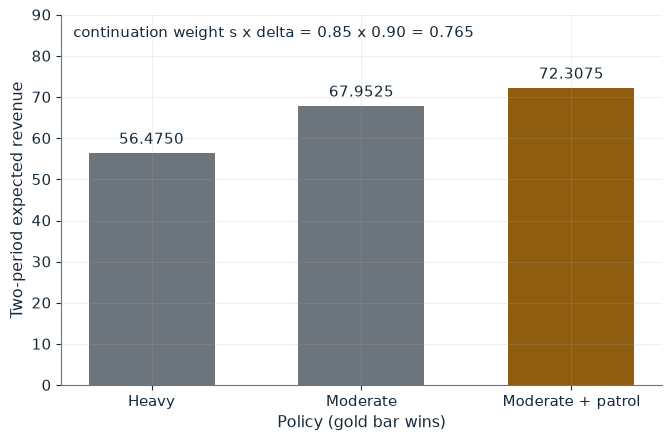

Continuation weight   0.765
Heavy                 56.4750
Moderate              67.9525
Moderate plus patrol  72.3075
Best policy           Moderate plus patrol

Worked steps:
  1. Weight = 0.85 x 0.90 = 0.765
  2. Heavy = 45 + 0.765 x 15 = 56.4750
  3. Moderate = 38.5 + 0.765 x 38.5 = 67.9525
  4. Patrol = 45.5 - 8 + 0.765 x 45.5 = 72.3075
  5. Highest: Moderate plus patrol

Hypothetical teaching numbers, not historical data. With survival 0.85 the ruler weights next year by 0.85 x 0.90 = 0.765. Heavy extraction is worth 45 + 0.765(15) = 56.4750, moderate extraction 38.5 + 0.765(38.5) = 67.9525, and moderate extraction with the patrol 45.5 - 8 + 0.765(45.5) = 72.3075. The best policy is moderate plus patrol.


In [2]:
show(bandit_picture(s=0.85))

Change one input, `s`, and hold the others at the book's values:

In [3]:
sweep(bandit_picture, 's', [0.2, 0.5, 0.85], {}, ['Continuation weight', 'Heavy', 'Moderate plus patrol', 'Best policy'])

s | Continuation weight | Heavy | Moderate plus patrol | Best policy
0.2 | 0.180 | 47.7000 | 45.6900 | Heavy extraction
0.5 | 0.450 | 51.7500 | 57.9750 | Moderate plus patrol
0.85 | 0.765 | 56.4750 | 72.3075 | Moderate plus patrol


A secure ruler prefers restraint plus the patrol (72.3075). At survival 0.20 the weight falls to 0.18 and heavy extraction (47.7) beats the patrol (45.69).

## 2. Voracity effect: windfall claims

Resources are \$150, services \$60 and transfers \$45; a \$30 windfall arrives and four blocs each demand \$12 more.

$$\frac{\Delta T}{\Delta W}=\frac{\$48}{\$30}=1.6, \qquad \$180-\$60-\$93=\$27, \qquad \$180-\$60-(\$45+\$18)=\$57$$

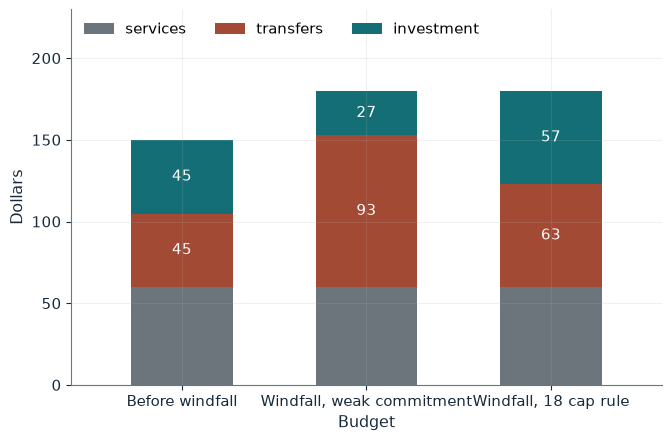

New claims                   48.00
Transfers                    93.00
Claim multiplier             1.6
Investment                   27.00
Investment under the 18 cap  57.00

Worked steps:
  1. New claims = 4 x 12 = 48; transfers = 45 + 48 = 93
  2. Claim multiplier = 48 / 30 = 1.6
  3. Investment = 180 - 60 - 93 = 27
  4. With the 18 cap: 180 - 60 - (45 + 18) = 57

Hypothetical teaching numbers, not historical data. Each of four blocs demands 12 more, so transfers rise by 48 to 93 and the claim multiplier is 48/30 = 1.6. Investment is 180 - 60 - 93 = 27, so investment falls 18 below its pre-windfall 45: the voracity effect. A binding 18 cap keeps investment at 57.


In [4]:
show(voracity_picture(d=12))

Change one input, `d`, and hold the others at the book's values:

In [5]:
sweep(voracity_picture, 'd', [6, 7.5, 12, 15], {}, ['Transfers', 'Claim multiplier', 'Investment'])

d | Transfers | Claim multiplier | Investment
6 | 69.00 | 0.8 | 51.00
7.5 | 75.00 | 1.0 | 45.00
12 | 93.00 | 1.6 | 27.00
15 | 105.00 | 2.0 | 15.00


Claims of 48 exceed the 30 windfall, so investment falls from 45 to 27. At 7.5 per bloc the claims exactly absorb the windfall; a binding cap of 18 keeps investment at 57.

## 3. Extractive institutions: the elite's tax choice

Potential output is 160 and extraction leaves $y(\tau)=160(1-\tau)$, of which the elite takes

$$R(\tau)=160\tau(1-\tau), \qquad \frac{dR}{d\tau}=160(1-2\tau)=0$$

A public input costing 8 raises potential output to 180: $180(0.75)=135$ and $33.75-30-8=-4.25$.

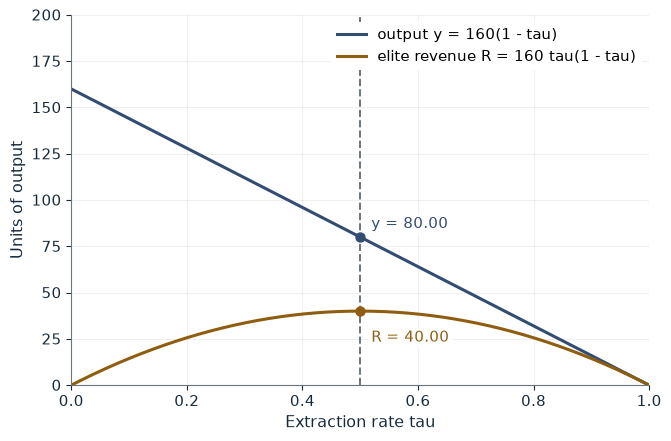

Output          80.00
Elite revenue   40.00
Producers keep  40.00

Worked steps:
  1. y = 160 x (1 - 0.50) = 80.00
  2. R = 0.50 x 80.00 = 40.00
  3. Producers keep 80.00 - 40.00 = 40.00

Hypothetical teaching numbers, not historical data. At tau = 0.50 output is 160(1 - 0.50) = 80.00, the elite takes 40.00 and producers keep 40.00. Revenue peaks where 160(1 - 2 tau) = 0, at tau = 0.5.


In [6]:
show(elite_picture(tau=0.5, public_input='no'))

Change one input, `tau`, and hold the others at the book's values:

In [7]:
sweep(elite_picture, 'tau', [0.25, 0.5, 0.75], {'public_input': 'no'}, ['Output', 'Elite revenue', 'Producers keep'])

tau | Output | Elite revenue | Producers keep
0.25 | 120.00 | 30.00 | 90.00
0.5 | 80.00 | 40.00 | 40.00
0.75 | 40.00 | 30.00 | 10.00


The elite's revenue peaks at tau = 0.5 (80 output, 40 each). At 0.25 output is 120 but the elite gets only 30. With the input (`public_input='yes'`) at 0.25, net social output rises to 127 while the elite's private change is -4.25, so it rejects the project.

## 4. Fiscal capacity: the officeholder's horizon

Base \$2,000, rate 0.18; a \$50 project raises collection capacity from 0.45 to 0.70.

$$T_0=0.45(0.18)(\$2{,}000)=\$162, \qquad T_1=0.70(0.18)(\$2{,}000)=\$252$$

$$\$90(1+0.92+0.92^2)=\$248.976, \qquad 0.40(\$90)=\$36$$

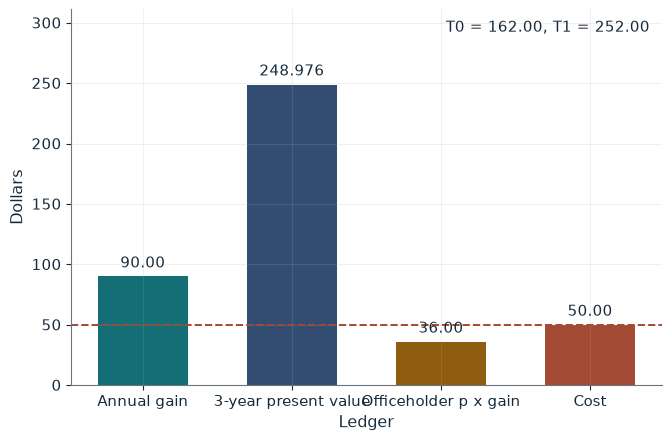

T0                    162.00
T1                    252.00
Annual gain           90.00
Present value         248.976
Net of cost           198.976
Officeholder benefit  36.00
Officeholder          Rejects

Worked steps:
  1. T0 = 0.45 x 0.18 x 2,000 = 162.00
  2. T1 = 0.70 x 0.18 x 2,000 = 252.00; gain 252.00 - 162.00 = 90.00
  3. PV = 90.00 x (1 + 0.92 + 0.8464) = 90.00 x 2.7664 = 248.976
  4. Net = 248.976 - 50 = 198.976
  5. Officeholder: 0.40 x 90.00 = 36.00 against 50, so it rejects the project
  6. Break-even retention = 50 / 90.00 = 0.556

Hypothetical teaching numbers, not historical data. Raising collection capacity from 0.45 to 0.70 lifts revenue from 162.00 to 252.00, a gain of 90.00 a year worth 90.00 x 2.7664 = 248.976 over three years, so the project is valuable at a cost of 50. The officeholder counts only 0.40 x 90.00 = 36.00, so it rejects the project; it would need a retention probability of at least 50 / 90.00 = 0.556.


In [8]:
show(capacity_picture(q1=0.70, p=0.40))

Change one input, `p`, and hold the others at the book's values:

In [9]:
sweep(capacity_picture, 'p', [0.4, 0.6, 0.8], {'q1': 0.7}, ['Present value', 'Officeholder benefit', 'Officeholder'])

p | Present value | Officeholder benefit | Officeholder
0.4 | 248.976 | 36.00 | Rejects
0.6 | 248.976 | 54.00 | Invests
0.8 | 248.976 | 72.00 | Invests


The project is worth 248.976 against a cost of 50, but an officeholder with a 40 percent chance of staying counts only 36 and rejects it. At 0.60 it expects 54 and invests; the break-even is 0.556.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

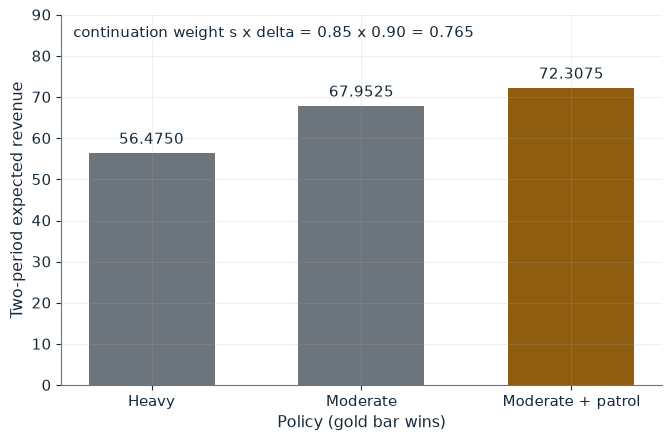

Continuation weight   0.765
Heavy                 56.4750
Moderate              67.9525
Moderate plus patrol  72.3075
Best policy           Moderate plus patrol

Worked steps:
  1. Weight = 0.85 x 0.90 = 0.765
  2. Heavy = 45 + 0.765 x 15 = 56.4750
  3. Moderate = 38.5 + 0.765 x 38.5 = 67.9525
  4. Patrol = 45.5 - 8 + 0.765 x 45.5 = 72.3075
  5. Highest: Moderate plus patrol

Hypothetical teaching numbers, not historical data. With survival 0.85 the ruler weights next year by 0.85 x 0.90 = 0.765. Heavy extraction is worth 45 + 0.765(15) = 56.4750, moderate extraction 38.5 + 0.765(38.5) = 67.9525, and moderate extraction with the patrol 45.5 - 8 + 0.765(45.5) = 72.3075. The best policy is moderate plus patrol.


In [10]:
show(bandit_picture(s=0.85))

## Practice

**1.** At survival 0.20, what are the heavy and patrol values?

<details><summary>Answer</summary>

Weight 0.18; heavy 45 + 0.18(15) = 47.7; patrol 37.5 + 0.18(45.5) = 45.69; heavy extraction wins.

</details>

**2.** If each of four blocs demands 15 from a 30 windfall, what are the claim multiplier and investment?

<details><summary>Answer</summary>

Claims 60, multiplier 60/30 = 2.0, transfers 105 and investment 180 - 60 - 105 = 15.

</details>

**3.** At capacity 0.70, what retention probability makes the officeholder indifferent?

<details><summary>Answer</summary>

p x 90 = 50, so p = 50/90 = 0.556.

</details>